### 2장 7강: 인덱싱 파이프라인 통합·증분 갱신
**학습 목표**

- 문서 수집부터 벡터 저장소 적재까지의 전 과정을 하나의 인덱싱 파이프라인으로 통합할 수 있다.
- SQLRecordManager 기반의 증분 갱신(Incremental Indexing)을 적용해 중복 비용 없이 변경된 문서만 반영할 수 있다.
- 갱신된 벡터 저장소와 LLM 모델을 연동하여 최신 문서 기반 질의응답을 검증할 수 있다.

In [1]:
import os
from dotenv import load_dotenv
from langchain_openai import OpenAIEmbeddings
# PostgreSQL pgvector 연동 모듈을 불러옵니다.
from langchain_postgres.vectorstores import PGVector

load_dotenv()

embeddings_model = OpenAIEmbeddings(
    model="text-embedding-3-small"
)

# 환경 변수에서 데이터베이스 접속 문자열을 읽어옵니다.
connection_url = os.getenv("DATABASE_URL")

# PGVector 저장소 객체를 생성하고 연결합니다.
vector_store = PGVector(
    embeddings=embeddings_model,     # 임베딩 모델 인스턴스 지정
    collection_name="integrated_university_rules", # 데이터를 보관할 컬렉션 테이블 이름
    connection=connection_url,  # 데이터베이스 접속 URL
    use_jsonb=True # 메타데이터를 PostgreSQL JSONB 형태로 저장
)

print("PostgreSQL + pgvector 연결 및 초기화 완료")

PostgreSQL + pgvector 연결 및 초기화 완료


#### SQLRecordManager를 활용한 증분 갱신(Incremental Indexing)
증분 갱신(Incremental Indexing)의 동작 원리
- **전체 재색인의 문제**: 기존 문서를 매번 전체 재저장하면 API 비용이 지속해서 청구되고 DB 입출력 병목이 발생합니다.
- **SQLRecordManager**: 문서의 출처(Source)와 내용의 해시(Hash) 값을 기록하는 일종의 '작업 장부'입니다.
- **index() 함수**: 장부를 조회하여 새로 생성된 청크는 추가(add), 수정된 청크는 업데이트(update), 변경이 없는 청크는 건너뜁니다(skip).


장부 테이블을 생성

In [2]:
from langchain_core.documents import Document

# 1차 등록 대상 문서 (2026 규정 및 장학 규정)
initial_documents = [
    Document(
        page_content="[도서관 규정] 학부생은 최대 5권까지 14일간 대출 가능합니다.",
        metadata={"source": "rules_library.txt", "category": "library", "year": 2026}
    ),
    Document(
        page_content="[장학금 규정] 직전 학기 평점 3.5 이상 시 장학금 대상입니다.",
        metadata={"source": "rules_scholarship.txt", "category": "scholarship", "year": 2026}
    )
]

초기 규정 문서 2건 인덱싱

In [3]:
from langchain_classic.indexes import index, SQLRecordManager

# 문서 인덱싱 기록을 추적할 장부(RecordManager)를 생성합니다.
record_manager = SQLRecordManager(
    namespace="integraed_university_rules",
    db_url=connection_url
)

record_manager.create_schema() # 추적용 테이블 스키마 생성

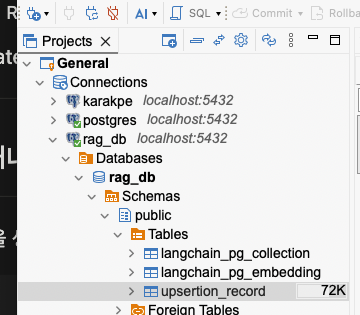
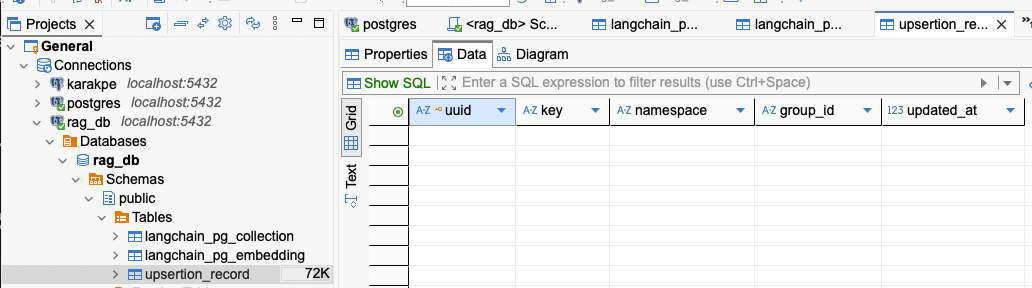
- upsertion_record 테이블 생성 확인

In [ ]:
first_result = index(
    docs_source=initial_documents,
    record_manager=record_manager,
    vector_store=vector_store,
    source_id_key="source", # 중복 여부를 판별하는 기준 메타데이터 키
    cleanup="incremental" 
) 

"""
cleanup=

none : 증분 관리 안해줌. 추가하면 추가됨 그냥
incremental : 중복된 레코드 있으면 삭제하고 새로 추가
full : 전체를 삭제하고 다시 추가
"""

print("=== [1차 인덱싱 결과] ===")
print(first_result) 

"""
=== [1차 인덱싱 결과] ===
{'num_added': 2, 'num_updated': 0, 'num_skipped': 0, 'num_deleted': 0}
---> 2개 추가됨
"""

/Users/myungjilee/Desktop/Kant/ax_study/.venv/lib/python3.13/site-packages/langchain_core/indexing/api.py:409: UserWarning: Using SHA-1 for document hashing. SHA-1 is *not* collision-resistant; a motivated attacker can construct distinct inputs that map to the same fingerprint. If this matters in your threat model, switch to a stronger algorithm such as 'blake2b', 'sha256', or 'sha512' by specifying  `key_encoder` parameter in the `index` or `aindex` function. 
  _warn_about_sha1()


=== [1차 인덱싱 결과] ===
{'num_added': 2, 'num_updated': 0, 'num_skipped': 0, 'num_deleted': 0}


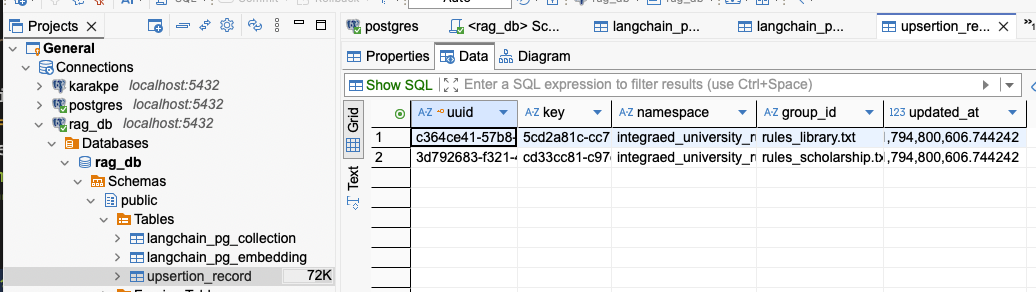

내용 변경 감지 및 건너뛰기(Skipped) 검증
- 기존 도서관 규정은 개정하고(수정), 장학 규정은 그대로 둔 채(유지) 다시 인덱싱합니다.

In [5]:
# 수정된 문서 목록: 도서관 규정 개정 및 장학 규정 동일 유지
updated_documents = [
    Document(
        page_content="[개정 도서관 규정] 학부생은 최대 7권까지 21일간 대출 가능합니다.", # 내용 변경 --> 중복 제거후 새로 생성 (incremental)
        metadata={"source": "rules_library.txt", "category": "library", "year": 2027}
    ),
    Document(
        page_content="[장학금 규정] 직전 학기 평점 3.5 이상 시 장학금 대상입니다.",       # 기존과 동일
        metadata={"source": "rules_scholarship.txt", "category": "scholarship", "year": 2026}
    )
]

# 2차 인덱싱을 실행합니다.
second_index_result = index(
    docs_source=updated_documents,
    record_manager=record_manager,
    vector_store=vector_store,
    cleanup="incremental",
    source_id_key="source"
)

print("=== [2차 증분 인덱싱 결과] ===")
print(second_index_result)

=== [2차 증분 인덱싱 결과] ===
{'num_added': 1, 'num_updated': 0, 'num_skipped': 1, 'num_deleted': 1}


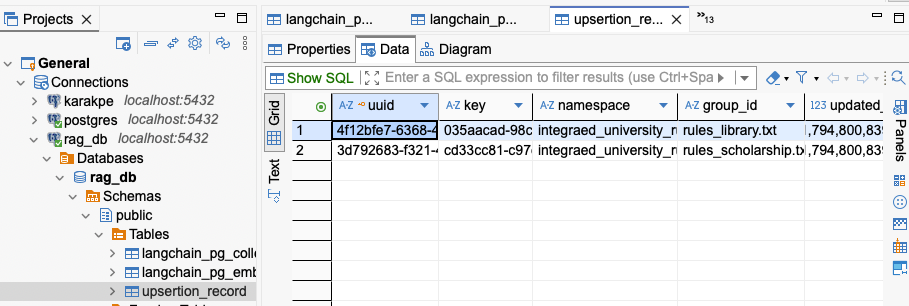
- 개정된 도서관 규정 rules_library.txt의 id값 바뀜 확인